# Lithology and mineral volumes

Lithology, what the rock is actually made of, falls out of the same logs once you stop reading
them one at a time. Density, neutron, and the photoelectric factor each respond differently to
quartz, calcite, dolomite, and anhydrite, so a few logs together pin down the mineral mix. The
library solves for the volume of each mineral at every depth as a small set of simultaneous
equations (the maths is in the *mineral solver* deep dive); here we just run it and read the
result on a real carbonate, **25/5-1**.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
REPO = Path.cwd()
while not (REPO / "petrophys").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))

from petrophys.io import read_las
from petrophys.workflow import run_dynamic_workflow
well = read_las(REPO / "petrophys" / "data" / "geolink" / "25_5-1.las")
run_dynamic_workflow(well, lithology="carbonate")     # writes VQUAR, VCALC, VDOLO, VANHY
[c for c in well.curves if c.startswith("V") and c[1:].isalpha()][:8]

['VCL', 'VCLAY', 'VCLGR', 'VCLSP', 'VCLND', 'VQUAR', 'VCALC', 'VDOLO']

The mineral volumes stack up to the rock matrix, with clay and porosity making up the rest.
The library's mineral template shows them as a cumulative track: quartz, clays, carbonates, and
porosity reading across to one.

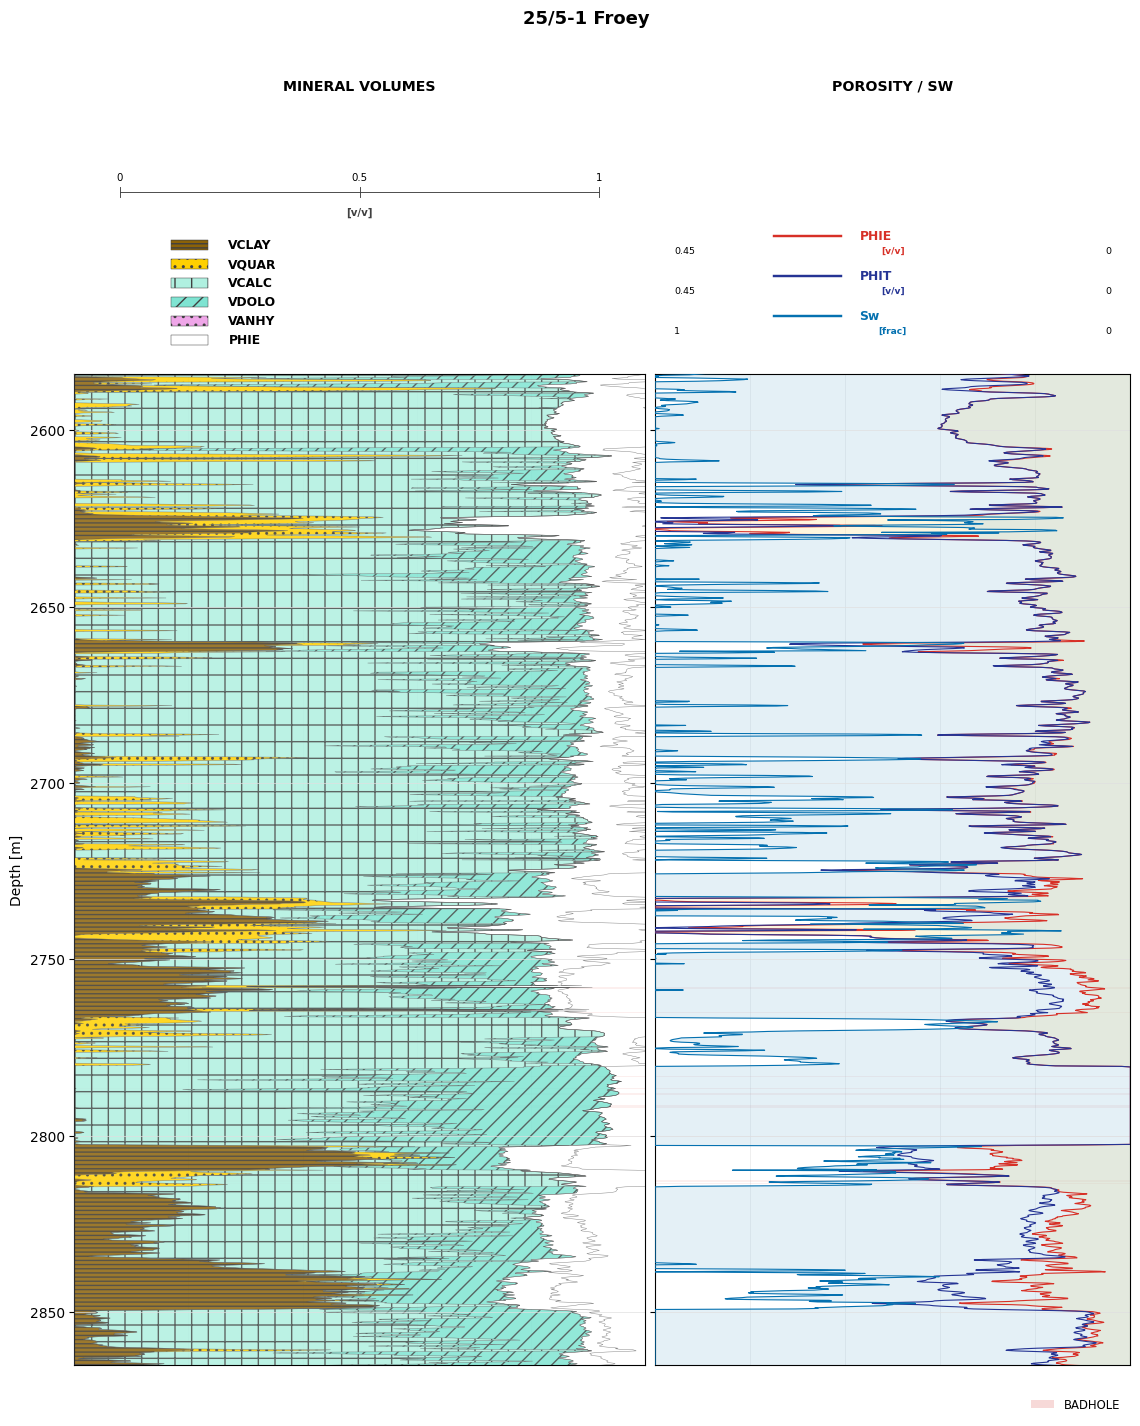

In [2]:
from petrophys.visualization import create_log_viewer
create_log_viewer(well, template_defaults="minerals", depth_range=(2584, 2865));

This is a clean dolomitic limestone, so the section solves mostly to calcite and dolomite. It is the photoelectric factor that cleanly separates the two carbonates: calcite reads about 5.1 and dolomite about 3.1, a contrast that, unlike density and neutron, barely moves with porosity. On density and neutron alone a porous calcite can mimic a tighter dolomite, which is the point made in detail in the *mineral solver* deep dive. Where the logs run through sand instead, the same solve returns quartz; the mineral set is
chosen to fit the basin.